# Forecasting data cleaning and preparation

This notebook contains the cleaning, imputation, aggregation, and outlier-review work used to prepare forecasting data. Baseline model fitting, backtesting, forecast selection, and interpretation are now contained in `Forecasting.ipynb`.


In [78]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [65]:
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "Data" / "processed"

dfs = {}

for file_path in PROCESSED_DIR.glob("*.csv"):
    key_name = file_path.stem
    try:
        # Load the CSV directly into the dictionary
        dfs[key_name] = pd.read_csv(file_path)
        print(f"Loaded: {file_path.name} -> dict key: '{key_name}'")
    except Exception as e:
        print(f"Skipped {file_path.name} due to error: {e}")

Loaded: foodshelf_county_month.csv -> dict key: 'foodshelf_county_month'
Loaded: foodshelf_issues_log.csv -> dict key: 'foodshelf_issues_log'
Loaded: foodshelf_site_month.csv -> dict key: 'foodshelf_site_month'
Loaded: mmg_mn_county_2022_2024.csv -> dict key: 'mmg_mn_county_2022_2024'
Loaded: poverty_2022_2024_clean.csv -> dict key: 'poverty_2022_2024_clean'
Skipped poverty_2022_2024_data_dictionary.csv due to error: Error tokenizing data. C error: Expected 5 fields in line 4, saw 6

Loaded: snap_2022_2024_clean.csv -> dict key: 'snap_2022_2024_clean'
Loaded: snap_2022_2026_clean.csv -> dict key: 'snap_2022_2026_clean'
Loaded: vehicle_access_2022_2024_clean.csv -> dict key: 'vehicle_access_2022_2024_clean'
Loaded: vehicle_access_2022_2024_data_dictionary.csv -> dict key: 'vehicle_access_2022_2024_data_dictionary'


In [71]:
# Unpack all dataframes from the dictionary into individual variables
foodshelf_county_month = dfs["foodshelf_county_month"]
foodshelf_issues_log = dfs["foodshelf_issues_log"]
foodshelf_site_month = dfs["foodshelf_site_month"]
mmg_mn_county_2022_2024 = dfs["mmg_mn_county_2022_2024"]
poverty_2022_2024_clean = dfs["poverty_2022_2024_clean"]
snap_2022_2024_clean = dfs["snap_2022_2024_clean"]
snap_2022_2026_clean = dfs["snap_2022_2026_clean"]
vehicle_access_2022_2024_clean = dfs["vehicle_access_2022_2024_clean"]
vehicle_access_2022_2024_data_dictionary = dfs["vehicle_access_2022_2024_data_dictionary"]

### Check on primary dataset: foodshelf_county_month

In [73]:
foodshelf_county_month.head(2)

,fips,county,month,visits,pounds,individuals,adults,children,seniors,n_sites,n_sites_reported,n_sites_missing
0,27001,Aitkin,2022-01-01,222.0,11249.0,547.0,238.0,114.0,195.0,6,6,0
1,27001,Aitkin,2022-02-01,222.0,11249.0,547.0,238.0,114.0,195.0,6,6,0


In [74]:
# Safely rename the column
foodshelf_county_month = foodshelf_county_month.rename(columns={"month": "date"})

# Find the index position of 'date'
date_idx = foodshelf_county_month.columns.get_loc("date")

# Insert the new columns right after 'date' in order
foodshelf_county_month.insert(date_idx + 1, "year_month", foodshelf_county_month["date"].str[:7])
foodshelf_county_month.insert(date_idx + 2, "year", foodshelf_county_month["date"].str[:4])
foodshelf_county_month.insert(date_idx + 3, "month_num", foodshelf_county_month["date"].str[5:7])

# Verify the updated layout
foodshelf_county_month.head()

,fips,county,date,year_month,year,month_num,visits,pounds,individuals,adults,children,seniors,n_sites,n_sites_reported,n_sites_missing
0,27001,Aitkin,2022-01-01,2022-01,2022,01,222.0,11249.0,547.0,238.0,114.0,195.0,6,6,0
1,27001,Aitkin,2022-02-01,2022-02,2022,02,222.0,11249.0,547.0,238.0,114.0,195.0,6,6,0
2,27001,Aitkin,2022-03-01,2022-03,2022,03,234.0,12729.0,562.0,224.0,126.0,212.0,5,5,0
3,27001,Aitkin,2022-04-01,2022-04,2022,04,297.0,14382.0,597.0,221.0,140.0,236.0,5,5,0
4,27001,Aitkin,2022-05-01,2022-05,2022,05,236.0,13290.0,593.0,250.0,131.0,212.0,5,5,0


#### Basic understanding

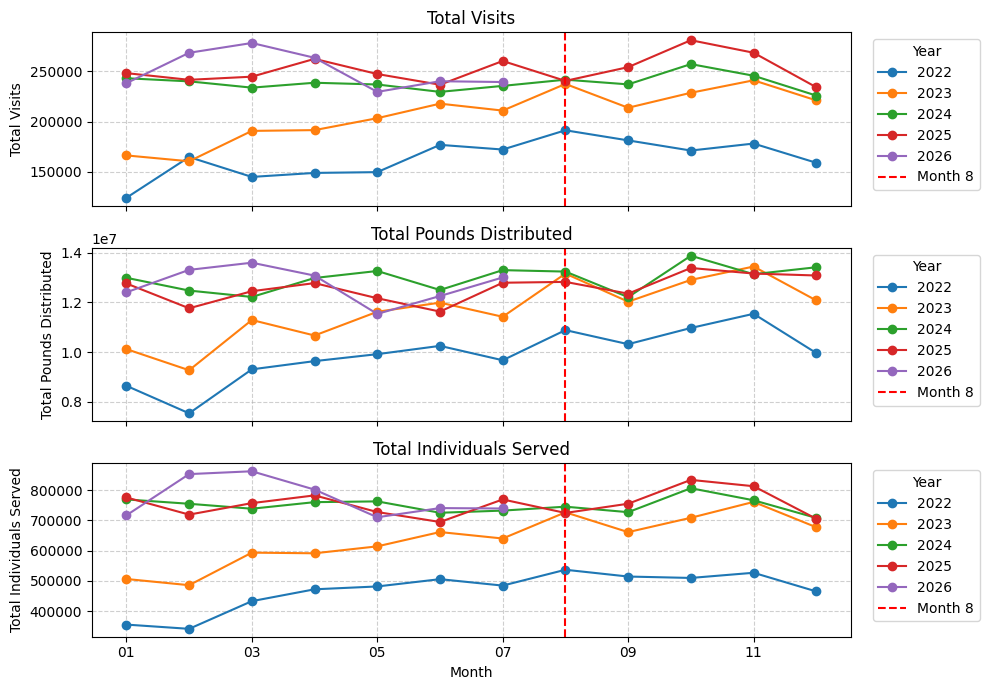

In [77]:

# Create a figure with 3 stacked subplots sharing the same X-axis
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

metrics = [
    ("visits", "Total Visits"),
    ("pounds", "Total Pounds Distributed"),
    ("individuals", "Total Individuals Served"),
]

for i, (col, title) in enumerate(metrics):
    # Group and pivot data for each metric using the correct dataframe name
    df_grouped = foodshelf_county_month.groupby(["year", "month_num"])[col].sum().reset_index()
    df_pivot = df_grouped.pivot(
        index="month_num", columns="year", values=col
    )

    # Plot on the corresponding subplot axis
    df_pivot.plot(kind="line", marker="o", ax=axes[i])

    # Add dashed vertical line at month 8 (index 7)
    axes[i].axvline(
        x=7, color="red", linestyle="--", linewidth=1.5, label="Month 8"
    )

    axes[i].set_title(title)
    axes[i].set_ylabel(title)
    axes[i].grid(True, linestyle="--", alpha=0.6)
    axes[i].legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")

axes[2].set_xlabel("Month")
plt.tight_layout()
plt.show()

Upward Growth Over Years: Across all three metrics (Total Visits, Total Pounds Distributed, and Total Individuals Served), older years like 2022 sit significantly lower, while 2024–2026 show massive overall escalations in demand.

Peak Seasons (Fall/Winter Surges): Spikes consistently occur toward the end of the year (Months 10 and 11), indicating increased food assistance needs during late autumn and the holiday season.

Month 8 Stability Point: Around Month 8 (marked by the red dashed line), trends across different years tend to converge or exhibit relative stability before experiencing distinct Q4 shifts.

In [89]:
foodshelf_county_month[foodshelf_county_month["n_sites_missing"] != 0]["county"].value_counts()

county
Beltrami       37
Clay           24
Hennepin       15
Olmsted        13
Grant          13
Cass            9
Itasca          8
Mille Lacs      7
Crow Wing       6
Koochiching     5
Aitkin          5
Wadena          4
Le Sueur        4
Ramsey          4
Faribault       3
Big Stone       3
Polk            3
Stevens         3
Stearns         3
Lake            3
Scott           3
St. Louis       2
Mahnomen        2
Otter Tail      2
Norman          2
Rice            1
Mower           1
Anoka           1
Sherburne       1
Kanabec         1
Jackson         1
Wabasha         1
Goodhue         1
Waseca          1
Washington      1
Name: count, dtype: int64

## Impute missing site-month data, then rebuild county totals

The site-month file is the detailed source behind the county-month file. Therefore, missing values are filled at the location/site level first, and the filled site values are then summed to county-month totals.

For every missing value, the function uses only information available by that month: (1) the same site one year earlier, (2) the median of that site's three most recent observations, (3) comparable sites in the same county, and (4) comparable sites elsewhere in Minnesota as a final fallback. Existing values, including real zeros, are never changed. Meal-program rows are excluded when rebuilding food-shelf county totals.

In [90]:
FOOD_SHELF_METRICS = ["visits", "pounds", "individuals", "adults", "children", "seniors"]
FORECAST_CUTOFF = pd.Timestamp("2026-07-31")


def _latest_peer_median(observed, metric, target_date, peer_mask):
    """Median of each peer site's latest known value on or before target_date."""
    history = observed.loc[
        peer_mask & observed["date"].le(target_date),
        ["site_id", "date", metric],
    ].dropna(subset=[metric])
    if history.empty:
        return np.nan
    latest_by_site = (
        history.sort_values("date")
        .groupby("site_id", dropna=False)[metric]
        .last()
    )
    return latest_by_site.median()


def impute_food_shelf_sites(site_month, metrics=None, cutoff="2026-07-31"):
    """Fill missing site-month metrics without changing observed values.

    Same-site donors are strictly earlier than the missing month. County/state
    peer donors may include reported peers from the same month because those
    values are already known when repairing the historical data.
    """
    metrics = FOOD_SHELF_METRICS if metrics is None else list(metrics)
    cutoff = pd.Timestamp(cutoff)
    data = site_month.copy()
    data["date"] = pd.to_datetime(data["month"])
    data["site_group_norm"] = data["site_group"].fillna("unknown").str.lower()
    data = data.loc[data["site_group_norm"].ne("meal")].copy()
    data = data.sort_values(["date", "county", "site_id"]).reset_index(drop=True)

    if data["date"].max() > cutoff:
        raise ValueError(f"Cutoff violation: site data extend past {cutoff.date()}.")

    # Keep an unchanged donor table so an imputed value never becomes a donor.
    observed = data.copy()

    for metric in metrics:
        if metric not in data.columns:
            raise KeyError(f"Missing required metric column: {metric}")

        filled_col = f"{metric}_imputed"
        method_col = f"{metric}_impute_method"
        flag_col = f"{metric}_was_imputed"
        data[filled_col] = data[metric]
        data[method_col] = np.where(data[metric].notna(), "observed", "unresolved")

        for idx, row in data.loc[data[metric].isna()].iterrows():
            site_history = observed.loc[
                observed["site_id"].eq(row["site_id"])
                & observed["date"].lt(row["date"])
                & observed[metric].notna()
            ].sort_values("date")

            lag_12_date = row["date"] - pd.DateOffset(years=1)
            lag_12 = site_history.loc[site_history["date"].eq(lag_12_date), metric]

            if not lag_12.empty:
                value = lag_12.iloc[-1]
                method = "same_site_lag_12"
            elif not site_history.empty:
                value = site_history[metric].tail(3).median()
                method = "same_site_recent_3_median"
            else:
                not_same_site = observed["site_id"].ne(row["site_id"])
                county_group_peers = (
                    observed["county"].eq(row["county"])
                    & observed["site_group_norm"].eq(row["site_group_norm"])
                    & not_same_site
                )
                value = _latest_peer_median(
                    observed, metric, row["date"], county_group_peers
                )
                method = "county_site_group_median"

                if pd.isna(value):
                    county_peers = observed["county"].eq(row["county"]) & not_same_site
                    value = _latest_peer_median(observed, metric, row["date"], county_peers)
                    method = "county_peer_median"

                if pd.isna(value):
                    state_group_peers = (
                        observed["site_group_norm"].eq(row["site_group_norm"])
                        & not_same_site
                    )
                    value = _latest_peer_median(
                        observed, metric, row["date"], state_group_peers
                    )
                    method = "state_site_group_median"

                if pd.isna(value):
                    value = _latest_peer_median(
                        observed, metric, row["date"], not_same_site
                    )
                    method = "state_peer_median"

            if pd.notna(value):
                data.at[idx, filled_col] = max(float(value), 0.0)
                data.at[idx, method_col] = method

        data[flag_col] = data[metric].isna() & data[filled_col].notna()

    return data


In [91]:
foodshelf_site_month_imputed = impute_food_shelf_sites(
    foodshelf_site_month,
    cutoff=FORECAST_CUTOFF,
)

imputation_summary = pd.concat(
    {
        metric: foodshelf_site_month_imputed.loc[
            foodshelf_site_month_imputed[f"{metric}_was_imputed"],
            f"{metric}_impute_method",
        ].value_counts()
        for metric in FOOD_SHELF_METRICS
    },
    axis=1,
).fillna(0).astype(int)
imputation_summary.loc["TOTAL"] = imputation_summary.sum()
imputation_summary

,visits,pounds,individuals,adults,children,seniors
same_site_lag_12,160,163,140,144,141,154
same_site_recent_3_median,89,91,88,93,98,99
county_site_group_median,60,54,58,59,64,76
county_peer_median,29,29,29,29,29,29
TOTAL,338,337,315,325,332,358


In [92]:
county_keys = ["fips", "county", "date"]
imputed_value_cols = [f"{metric}_imputed" for metric in FOOD_SHELF_METRICS]
imputed_flag_cols = [f"{metric}_was_imputed" for metric in FOOD_SHELF_METRICS]

county_imputed_totals = (
    foodshelf_site_month_imputed.groupby(county_keys, as_index=False)[imputed_value_cols]
    .sum(min_count=1)
)
county_imputed_site_counts = (
    foodshelf_site_month_imputed.groupby(county_keys, as_index=False)[imputed_flag_cols]
    .sum()
    .rename(columns={
        f"{metric}_was_imputed": f"{metric}_n_imputed_sites"
        for metric in FOOD_SHELF_METRICS
    })
)

county_reported = foodshelf_county_month.rename(columns={
    metric: f"{metric}_reported" for metric in FOOD_SHELF_METRICS
}).copy()
county_reported["date"] = pd.to_datetime(county_reported["date"])

foodshelf_county_month_imputed = (
    county_reported
    .merge(county_imputed_totals, on=county_keys, how="left", validate="one_to_one")
    .merge(county_imputed_site_counts, on=county_keys, how="left", validate="one_to_one")
    .sort_values(["county", "date"])
    .reset_index(drop=True)
)

for metric in FOOD_SHELF_METRICS:
    foodshelf_county_month_imputed[f"{metric}_imputed_amount"] = (
        foodshelf_county_month_imputed[f"{metric}_imputed"]
        - foodshelf_county_month_imputed[f"{metric}_reported"].fillna(0)
    )

assert foodshelf_county_month_imputed["date"].max() <= FORECAST_CUTOFF
foodshelf_county_month_imputed.head()

,fips,county,date,year_month,year,month_num,visits_reported,pounds_reported,individuals_reported,adults_reported,...,individuals_n_imputed_sites,adults_n_imputed_sites,children_n_imputed_sites,seniors_n_imputed_sites,visits_imputed_amount,pounds_imputed_amount,individuals_imputed_amount,adults_imputed_amount,children_imputed_amount,seniors_imputed_amount
0,27001,Aitkin,2022-01-01,2022-01,2022,01,222.0,11249.0,547.0,238.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,27001,Aitkin,2022-02-01,2022-02,2022,02,222.0,11249.0,547.0,238.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,27001,Aitkin,2022-03-01,2022-03,2022,03,234.0,12729.0,562.0,224.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,27001,Aitkin,2022-04-01,2022-04,2022,04,297.0,14382.0,597.0,221.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,27001,Aitkin,2022-05-01,2022-05,2022,05,236.0,13290.0,593.0,250.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Compare each county's reported and imputed trend

Change COUNTY_TO_PLOT to inspect another county. Red points mark months where at least one site was imputed for that metric.

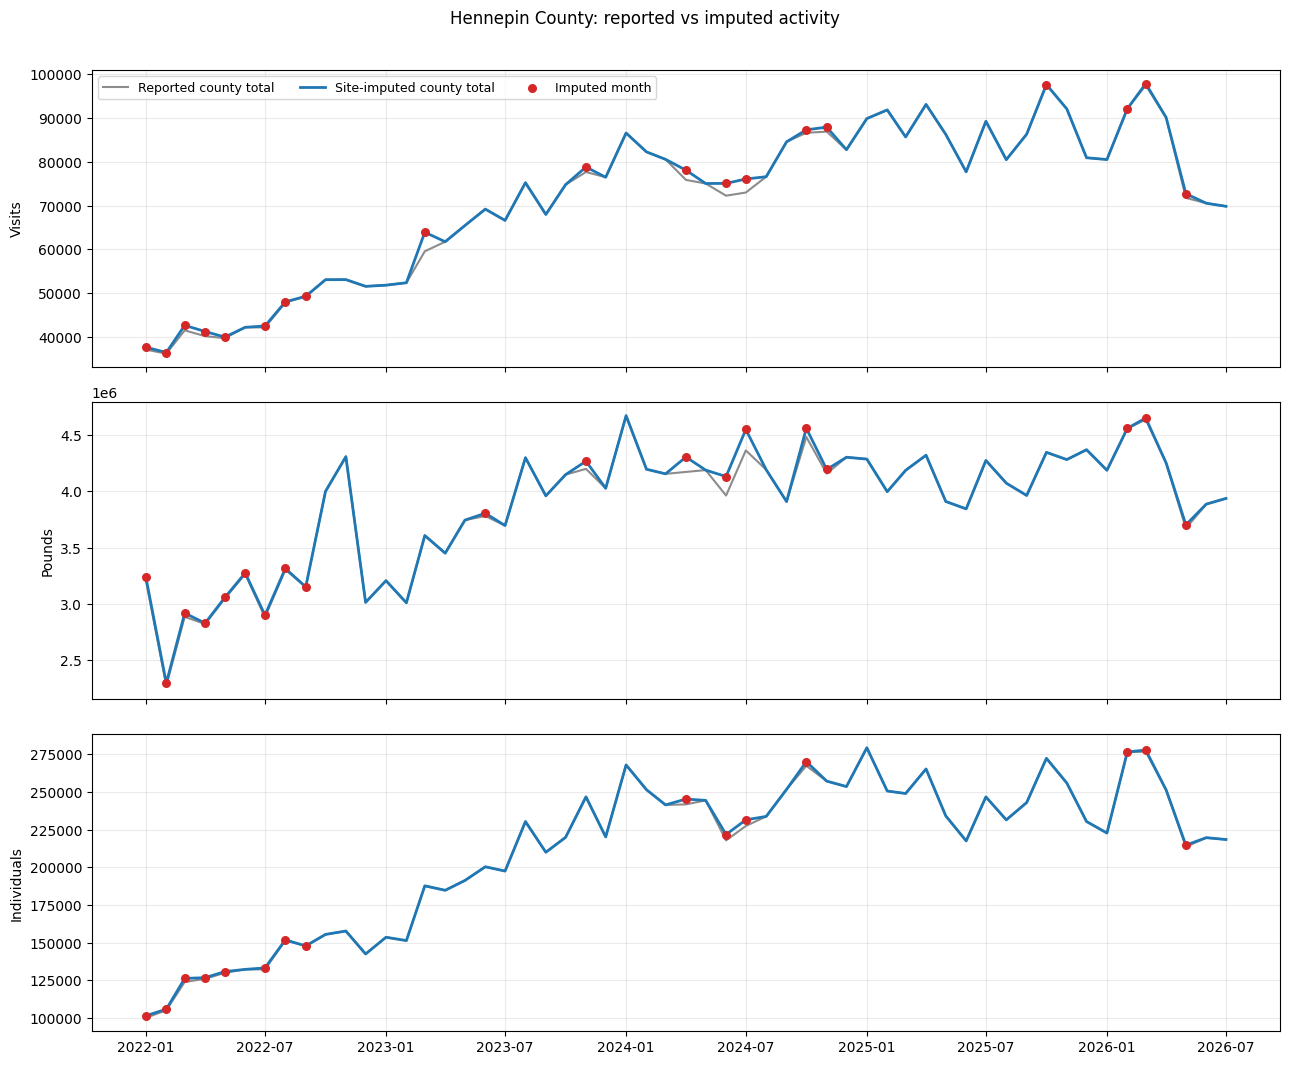

In [93]:
def plot_county_imputation(county_name, metrics=("visits", "pounds", "individuals")):
    county_data = foodshelf_county_month_imputed.loc[
        foodshelf_county_month_imputed["county"].str.casefold().eq(county_name.casefold())
    ].sort_values("date")
    if county_data.empty:
        raise ValueError(f"County not found: {county_name}")

    fig, axes = plt.subplots(len(metrics), 1, figsize=(13, 3.5 * len(metrics)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, metric in zip(axes, metrics):
        ax.plot(
            county_data["date"], county_data[f"{metric}_reported"],
            color="0.55", label="Reported county total",
        )
        ax.plot(
            county_data["date"], county_data[f"{metric}_imputed"],
            color="tab:blue", linewidth=2, label="Site-imputed county total",
        )
        changed = county_data[f"{metric}_n_imputed_sites"].fillna(0).gt(0)
        ax.scatter(
            county_data.loc[changed, "date"],
            county_data.loc[changed, f"{metric}_imputed"],
            color="tab:red", s=30, zorder=3, label="Imputed month",
        )
        ax.set_ylabel(metric.title())
        ax.grid(alpha=0.25)

    axes[0].legend(ncol=3, fontsize=9)
    fig.suptitle(f"{county_data['county'].iloc[0]} County: reported vs imputed activity", y=1.01)
    fig.tight_layout()
    return fig, axes


COUNTY_TO_PLOT = "Hennepin"
plot_county_imputation(COUNTY_TO_PLOT);

The original county table remains unchanged. Use foodshelf_county_month_imputed as a separate sensitivity series. During the August backtests, rerun this imputation inside each historical July cutoff and never impute the held-out August outcome.

In [116]:
# Rows where at least one primary outcome was imputed
imputed_rows = foodshelf_site_month_imputed[
    foodshelf_site_month_imputed[
        [
            "visits_was_imputed",
            "pounds_was_imputed",
            "individuals_was_imputed",
        ]
    ].any(axis=1)
]

imputed_rows[
    [
        "site_id",
        "county",
        "date",
        "visits",
        "visits_imputed",
        "visits_impute_method",
        "pounds",
        "pounds_imputed",
        "pounds_impute_method",
        "individuals",
        "individuals_imputed",
        "individuals_impute_method",
    ]
].head(5)

,site_id,county,date,visits,visits_imputed,visits_impute_method,pounds,pounds_imputed,pounds_impute_method,individuals,individuals_imputed,individuals_impute_method
23,14807.0,Big Stone,2022-01-01,NaN,41.0,county_site_group_median,NaN,4485.0,county_site_group_median,NaN,113.0,county_site_group_median
45,14416.0,Cass,2022-01-01,NaN,68.0,county_peer_median,NaN,3976.0,county_peer_median,NaN,178.0,county_peer_median
52,1107.0,Clay,2022-01-01,NaN,50.0,county_site_group_median,NaN,2567.0,county_site_group_median,NaN,118.0,county_site_group_median
59,14660.0,Clay,2022-01-01,NaN,50.0,county_site_group_median,NaN,2567.0,county_site_group_median,NaN,118.0,county_site_group_median
75,14526.0,Crow Wing,2022-01-01,NaN,101.0,county_peer_median,NaN,10302.0,county_peer_median,NaN,225.0,county_peer_median


### Checking the Outliers

### Recommended outlier workflow

```
Original site-month observations
              |
              v
 Remove missing/imputed values from outlier fitting
              |
              v
 Compare each site with its own historical pattern
              |
              +--> Large month-to-month change
              +--> Different from rolling median
              +--> Different from same month in prior years
              |
              v
 Compare site with similar sites in the same county
              |
              v
 Check suspicious ratios
 pounds/visit and individuals/visit
              |
              v
 Plot and manually review flagged observations
              |
              v
 Keep legitimate spikes; correct or exclude probable errors
              |
              v
 Aggregate reviewed site values to county totals
```

In [123]:
### 1\. Start with the existing outlier flag
existing_outliers = foodshelf_site_month_imputed.loc[
    foodshelf_site_month_imputed["flag_outlier"].fillna(False),
    [
        "site_id",
        "county",
        "date",
        "visits",
        "pounds",
        "individuals",
        "flag_outlier",
    ],
].sort_values(["county", "site_id", "date"])

existing_outliers.head()

,site_id,county,date,visits,pounds,individuals,flag_outlier
1317,13633.0,Chisago,2022-04-01,49.0,59960.0,147.0,True
9760,14660.0,Clay,2023-10-01,333.0,21613.0,1527.0,True
10732,14660.0,Clay,2023-12-01,287.0,13744.0,1452.0,True
22750,14188.0,Dakota,2026-02-01,7336.0,233570.0,25993.0,True
19570,15308.0,Dakota,2025-07-01,1508.0,19281.0,3919.0,True


In [126]:
### 2\. Visualize one site’s history

def plot_site_outliers(site_id, metric="visits"):
    data = (
        foodshelf_site_month_imputed.loc[
            foodshelf_site_month_imputed["site_id"] == site_id
        ]
        .sort_values("date")
        .copy()
    )

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        data["date"],
        data[metric],
        marker="o",
        color="tab:blue",
        label="Observed",
    )

    imputed = data[f"{metric}_was_imputed"]
    ax.scatter(
        data.loc[imputed, "date"],
        data.loc[imputed, f"{metric}_imputed"],
        color="tab:orange",
        marker="s",
        s=60,
        label="Imputed",
    )

    outliers = data["flag_outlier"].fillna(False)
    ax.scatter(
        data.loc[outliers, "date"],
        data.loc[outliers, metric],
        color="red",
        marker="X",
        s=100,
        label="Existing outlier flag",
    )

    ax.set_title(f"Site {site_id}: {metric}")
    ax.set_ylabel(metric.title())
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

In [ ]:
### 3\. Use a rolling robust outlier rule

def add_rolling_outlier_flag(data, metric, window=12, threshold=3.5):
    result = data.sort_values(["site_id", "date"]).copy()

    log_value = np.log1p(result[metric])

    rolling_median = log_value.groupby(result["site_id"]).transform(
        lambda x: x.shift(1).rolling(window, min_periods=4).median()
    )

    absolute_deviation = (log_value - rolling_median).abs()

    rolling_mad = absolute_deviation.groupby(result["site_id"]).transform(
        lambda x: x.shift(1).rolling(window, min_periods=4).median()
    )

    robust_score = 0.6745 * (log_value - rolling_median) / rolling_mad.replace(0, np.nan)

    result[f"{metric}_robust_score"] = robust_score
    result[f"{metric}_outlier"] = robust_score.abs() > threshold

    # Imputed values should not be presented as observed outliers.
    result.loc[
        result[f"{metric}_was_imputed"],
        f"{metric}_outlier",
    ] = False

    return result

#### meal gap dataset

In [119]:
mmg_mn_county_2022_2024.columns

Index(['fips', 'county', 'year', 'fi_rate', 'fi_persons', 'child_fi_rate',
       'fi_children', 'fi_rate_black', 'fi_rate_hispanic', 'fi_rate_white_nh',
       'snap_threshold', 'pct_fi_below_snap_threshold',
       'pct_fi_above_snap_threshold', 'pct_fi_children_below_185fpl',
       'pct_fi_children_above_185fpl', 'cost_per_meal',
       'weekly_dollars_needed_per_fi', 'annual_food_budget_shortfall',
       'rucc_2023', 'source_file', 'rural'],
      dtype='object')